In [2]:
import numpy as np
import pandas as pd


In [3]:
data = pd.read_csv('HR_comma_sep.csv') # Loading the data
data.info() # Info of the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   sales                  14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


In [4]:
data.head() # 1st five records

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [5]:
# checking missing values
data.isna().sum()

,0
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
sales,0
salary,0


In [6]:
data.describe() # data statistical description

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
count,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000,14999.000000
mean,0.612834,0.716102,3.803054,201.050337,3.498233,0.144610,0.238083,0.021268
std,0.248631,0.171169,1.232592,49.943099,1.460136,0.351719,0.425924,0.144281
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000
25%,0.440000,0.560000,3.000000,156.000000,3.000000,0.000000,0.000000,0.000000
50%,0.640000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000
75%,0.820000,0.870000,5.000000,245.000000,4.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,7.000000,310.000000,10.000000,1.000000,1.000000,1.000000


## 2. Understanding Factors Contributing to Employee Turnover (EDA)

### 2.1. Heatmap of the Correlation Matrix

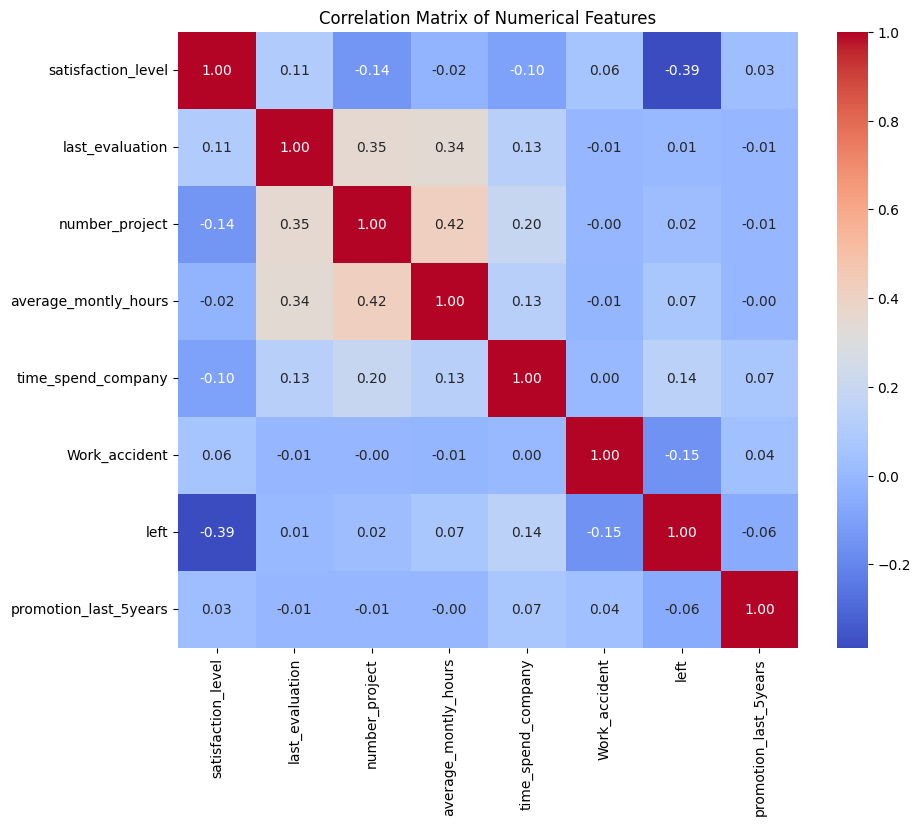

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for correlation matrix
numerical_cols = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(data[numerical_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### 2.2. Distribution Plots of Key Numerical Features

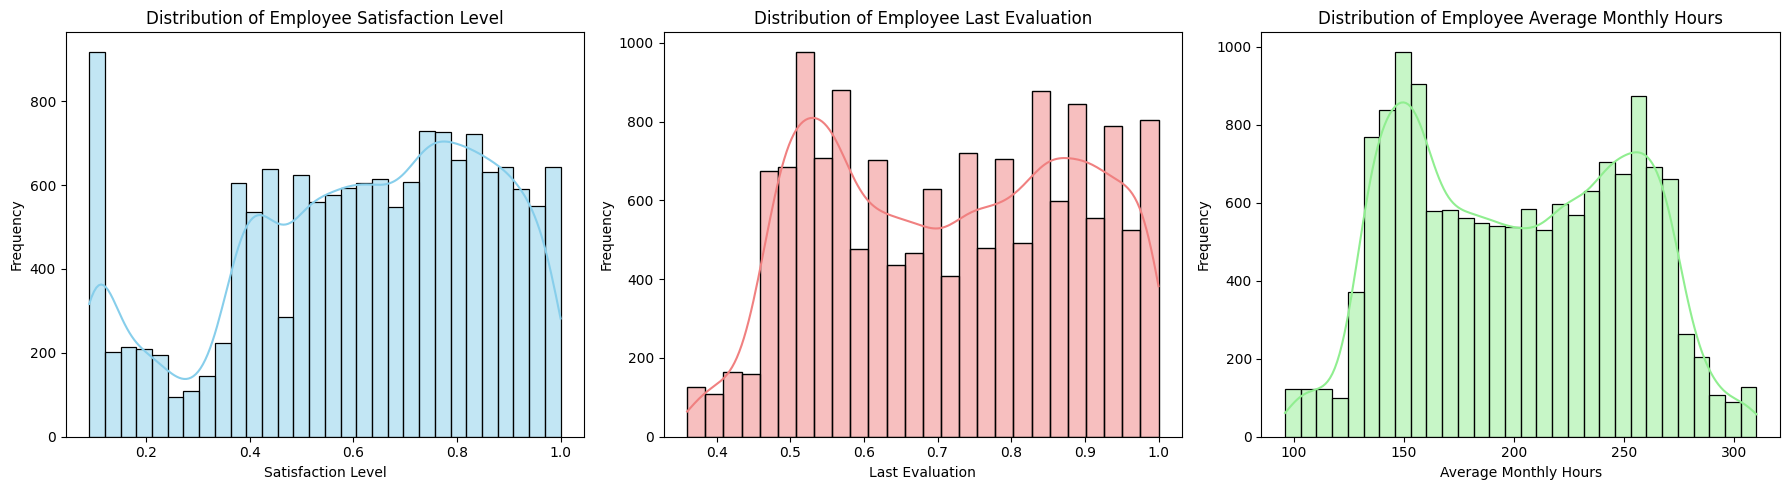

In [8]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.histplot(data['satisfaction_level'], kde=True, color='skyblue')
plt.title('Distribution of Employee Satisfaction Level')
plt.xlabel('Satisfaction Level')
plt.ylabel('Frequency')

plt.subplot(1, 3, 2)
sns.histplot(data['last_evaluation'], kde=True, color='lightcoral')
plt.title('Distribution of Employee Last Evaluation')
plt.xlabel('Last Evaluation')
plt.ylabel('Frequency')

plt.subplot(1, 3, 3)
sns.histplot(data['average_montly_hours'], kde=True, color='lightgreen')
plt.title('Distribution of Employee Average Monthly Hours')
plt.xlabel('Average Monthly Hours')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

### 2.3. Bar Plot of Employee Project Count by Turnover

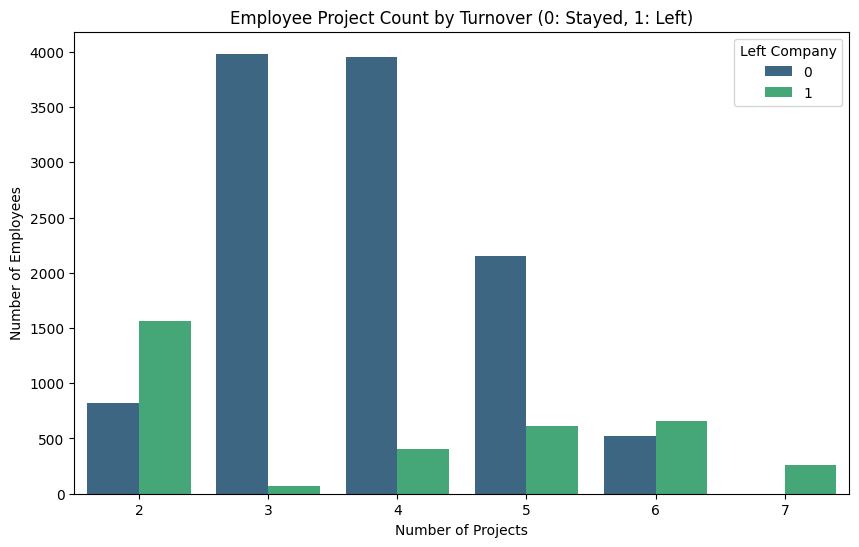

In [9]:
plt.figure(figsize=(10, 6))
sns.countplot(x='number_project', hue='left', data=data, palette='viridis')
plt.title('Employee Project Count by Turnover (0: Stayed, 1: Left)')
plt.xlabel('Number of Projects')
plt.ylabel('Number of Employees')
plt.legend(title='Left Company')
plt.show()

#### Inferences from the Project Count Plot:
*   **Employees with 2 projects**: A large proportion of employees with only 2 projects left the company. This suggests that having too few projects might indicate disengagement or lack of challenging work.
*   **Employees with 3, 4, 5 projects**: The majority of employees in these categories stayed with the company. This range seems to be optimal for employee retention.
*   **Employees with 6 or 7 projects**: A significant number of employees working on 6 or 7 projects also left. This could indicate overwork or burnout, as managing too many projects can lead to stress and dissatisfaction.

## 3. Perform Clustering of Employees Who Left

### 3.1. Choose columns `satisfaction_level`, `last_evaluation`, and `left`

In [10]:
# Filter data for employees who left (left = 1)
left_employees = data[data['left'] == 1]

# Select features for clustering: satisfaction_level and last_evaluation
X_clustering = left_employees[['satisfaction_level', 'last_evaluation']]

print("Shape of data for clustering (employees who left):", X_clustering.shape)
display(X_clustering.head())

Shape of data for clustering (employees who left): (3571, 2)


,satisfaction_level,last_evaluation
0,0.38,0.53
1,0.80,0.86
2,0.11,0.88
3,0.72,0.87
4,0.37,0.52


### Determining Optimal Number of Clusters (K) using the Elbow Method
To perform K-means clustering effectively, we first need to determine the optimal number of clusters. The Elbow Method helps us find this by plotting the Within-Cluster Sum of Squares (WCSS) against the number of clusters.

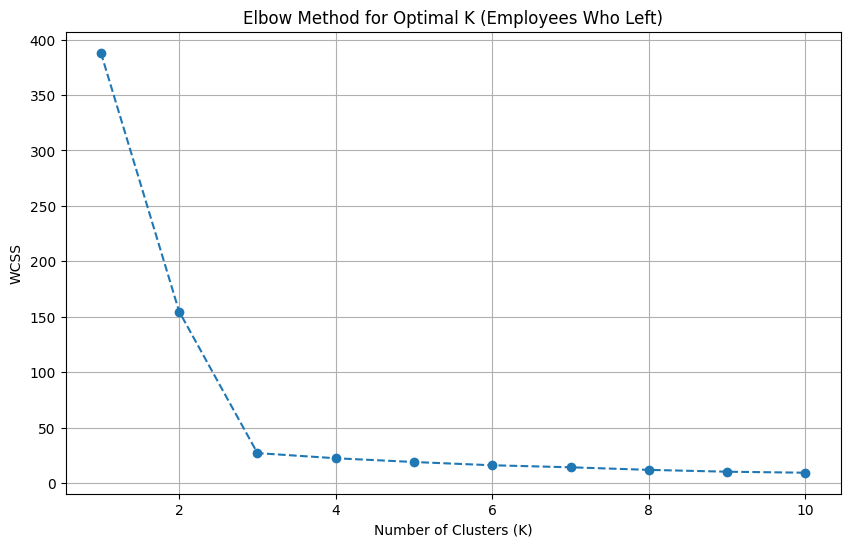

In [11]:
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_clustering)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K (Employees Who Left)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

### 3.2. K-means Clustering of Employees Who Left into 3 Clusters
Based on the elbow plot, an 'elbow' often appears around 3 clusters, suggesting that 3 is a reasonable number of clusters for this dataset. We will proceed with 3 clusters as specified in the problem description.

In [12]:
n_clusters = 3 # Chosen based on the Elbow Method or problem statement
kmeans = KMeans(n_clusters=n_clusters, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_clustering)

# Add the cluster labels back to the 'left_employees' DataFrame for analysis
left_employees_clustered = left_employees.copy()
left_employees_clustered['cluster'] = clusters

print(f"Employees who left are grouped into {n_clusters} clusters:")
display(left_employees_clustered.head())

Employees who left are grouped into 3 clusters:


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary,cluster
0,0.38,0.53,2,157,3,0,1,0,sales,low,0
1,0.80,0.86,5,262,6,0,1,0,sales,medium,1
2,0.11,0.88,7,272,4,0,1,0,sales,medium,2
3,0.72,0.87,5,223,5,0,1,0,sales,low,1
4,0.37,0.52,2,159,3,0,1,0,sales,low,0


Now, let's visualize these clusters to understand their characteristics based on 'satisfaction_level' and 'last_evaluation'.

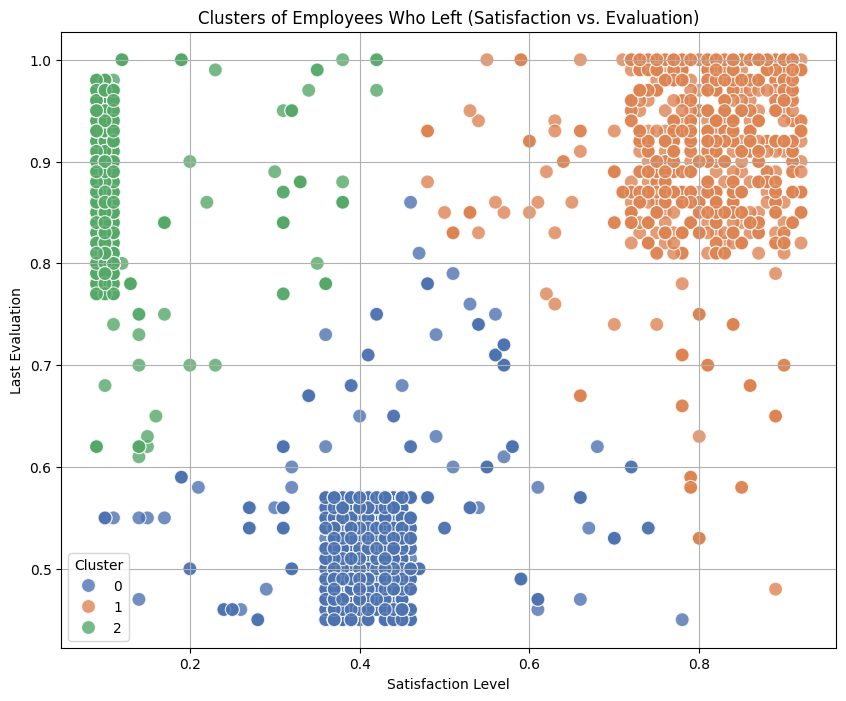

In [13]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='satisfaction_level', y='last_evaluation', hue='cluster', data=left_employees_clustered, palette='deep', s=100, alpha=0.8)
plt.title('Clusters of Employees Who Left (Satisfaction vs. Evaluation)')
plt.xlabel('Satisfaction Level')
plt.ylabel('Last Evaluation')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

### 3.3. Thoughts on the Employee Clusters (Satisfaction and Evaluation Factors)
This scatter plot visually separates the employees who left into three distinct clusters based on their satisfaction and evaluation scores. To further understand these clusters, let's look at the average characteristics of each cluster.

In [14]:
cluster_summary = left_employees_clustered.groupby('cluster')[['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours', 'time_spend_company']].mean()
print("Cluster Summary (Mean values of key features for employees who left by cluster):")
display(cluster_summary)

Cluster Summary (Mean values of key features for employees who left by cluster):


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company
cluster,,,,,
0,0.410145,0.516982,2.176970,150.091515,3.069697
1,0.808516,0.911709,4.505629,241.857728,5.042989
2,0.111155,0.869301,6.116525,271.978814,4.079449


#### Inferences from Cluster Summary:
*   **Cluster 0 (Low Satisfaction, Moderate Evaluation)**: These employees have low satisfaction but moderate evaluation. They tend to have fewer projects and lower average monthly hours. This group might consist of employees who became disengaged due to lack of challenging work, felt underutilized, or were generally unhappy despite performing adequately.
*   **Cluster 1 (High Satisfaction, High Evaluation, High Workload)**: This group shows high satisfaction and high evaluation, but also high average monthly hours and a higher number of projects. This could represent high-performing employees who eventually left due to burnout from excessive workload, lack of career growth despite good performance, or better opportunities elsewhere after being highly valued.
*   **Cluster 2 (Very Low Satisfaction, High Evaluation, Extreme Workload)**: This is a critical group with extremely low satisfaction but surprisingly high evaluations. They also have the highest average monthly hours and number of projects. This pattern strongly suggests burnout. These employees were likely high performers pushed to their limits, leading to severe dissatisfaction and eventual departure despite being highly valued for their output.

## 4. Handling Class Imbalance with SMOTE Technique

Before applying SMOTE, we need to preprocess the data:
*   Convert categorical columns to numerical using one-hot encoding.
*   Separate features (X) and target (y).
*   Split the dataset into training and testing sets with an 80:20 ratio, ensuring stratification.

In [15]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import pandas as pd

# 4.1. Pre-process the data by converting categorical columns to numerical columns
# Identify categorical and numerical variables
categorical_vars = ['sales', 'salary'] # 'Work_accident', 'promotion_last_5years', 'left' are already numerical (0/1)
numerical_vars = [col for col in data.columns if col not in categorical_vars + ['left']]

# Apply one-hot encoding to categorical variables
data_encoded = pd.get_dummies(data, columns=categorical_vars, drop_first=True)

# Separate features (X) and target (y)
X = data_encoded.drop('left', axis=1)
y = data_encoded['left']

print("Shape of features (X) after one-hot encoding:", X.shape)
print("Shape of target (y) after one-hot encoding:", y.shape)
display(X.head())

Shape of features (X) after one-hot encoding: (14999, 18)
Shape of target (y) after one-hot encoding: (14999,)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False


### 4.2. Stratified Split of the Dataset (80:20)

In [16]:
# Split the data into training and testing sets (80:20 ratio) with stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Distribution of 'left' in y_train before SMOTE:")
display(y_train.value_counts(normalize=True))
print("Distribution of 'left' in y_test:")
display(y_test.value_counts(normalize=True))

Shape of X_train: (11999, 18)
Shape of X_test: (3000, 18)
Distribution of 'left' in y_train before SMOTE:


,proportion
left,
0,0.761897
1,0.238103


Distribution of 'left' in y_test:


,proportion
left,
0,0.762
1,0.238


### 4.3. Upsampling the Training Dataset using SMOTE

Shape of X_train after SMOTE: (18284, 18)
Shape of y_train after SMOTE: (18284,)
Distribution of 'left' in y_train after SMOTE:


,proportion
left,
0,0.5
1,0.5


/tmp/ipykernel_7825/2588626323.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_smote, palette='viridis')


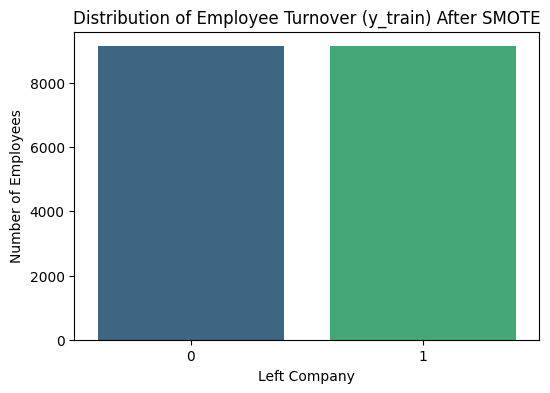

In [17]:
# Apply SMOTE to the training data to balance the classes
smote = SMOTE(random_state=123)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Shape of X_train after SMOTE:", X_train_smote.shape)
print("Shape of y_train after SMOTE:", y_train_smote.shape)
print("Distribution of 'left' in y_train after SMOTE:")
display(y_train_smote.value_counts(normalize=True))

# Visualize the balanced distribution
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train_smote, palette='viridis')
plt.title('Distribution of Employee Turnover (y_train) After SMOTE')
plt.xlabel('Left Company')
plt.ylabel('Number of Employees')
plt.show()

The `y_train_smote` now shows a balanced distribution of the target variable, which is crucial for training a robust machine learning model that doesn't bias towards the majority class.

## 5. Perform 5-fold Cross-Validation Model Training and Evaluate Performance

To ensure robust evaluation and compare different models, we will use 5-fold stratified cross-validation. StratifiedKFold is particularly important here to maintain the class distribution in each fold, especially since we've balanced our training data with SMOTE. We will evaluate models using various metrics and a classification report.

In [18]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def train_evaluate_cv_model(model, X_train_smote, y_train_smote, X_test, y_test, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    oof_preds = np.zeros(len(X_train_smote))
    test_preds = np.zeros(len(X_test))
    test_probas = np.zeros(len(X_test))

    fold_reports = []
    test_roc_auc_scores = []

    print(f"--- Training {model.__class__.__name__} with {n_splits}-fold Cross-Validation ---")

    for fold, (train_index, val_index) in enumerate(skf.split(X_train_smote, y_train_smote)):
        print(f"\nFold {fold+1}/{n_splits}")
        X_train_fold, X_val_fold = X_train_smote.iloc[train_index], X_train_smote.iloc[val_index]
        y_train_fold, y_val_fold = y_train_smote.iloc[train_index], y_train_smote.iloc[val_index]

        model.fit(X_train_fold, y_train_fold)
        oof_preds[val_index] = model.predict(X_val_fold)

        # Collect test predictions from each fold to average later
        test_preds_fold = model.predict(X_test)
        test_probas_fold = model.predict_proba(X_test)[:, 1]
        test_preds += test_preds_fold
        test_probas += test_probas_fold

        # Evaluate on current fold's validation set
        val_report = classification_report(y_val_fold, oof_preds[val_index], output_dict=True)
        fold_reports.append(val_report)
        print("Validation Set Classification Report:")
        print(classification_report(y_val_fold, oof_preds[val_index]))

    # Average test predictions (simple majority vote for class, average for probability)
    final_test_preds = (test_preds / n_splits > 0.5).astype(int)
    final_test_probas = test_probas / n_splits

    # Final evaluation on the unseen test set
    print(f"\n--- Final Evaluation of {model.__class__.__name__} on Test Set ---")
    print("Test Set Classification Report:")
    print(classification_report(y_test, final_test_preds))
    test_roc_auc = roc_auc_score(y_test, final_test_probas)
    print(f"Test Set ROC AUC: {test_roc_auc:.4f}")

    # Plot Confusion Matrix for Test Set
    cm = confusion_matrix(y_test, final_test_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model.__class__.__name__} (Test Set)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return final_test_preds, final_test_probas, test_roc_auc

### 5.1. Train a Logistic Regression model, apply a 5-fold CV, and plot the classification report.

--- Training LogisticRegression with 5-fold Cross-Validation ---

Fold 1/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.79      0.80      1829
           1       0.80      0.80      0.80      1828

    accuracy                           0.80      3657
   macro avg       0.80      0.80      0.80      3657
weighted avg       0.80      0.80      0.80      3657


Fold 2/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.76      0.79      1829
           1       0.77      0.83      0.80      1828

    accuracy                           0.79      3657
   macro avg       0.80      0.79      0.79      3657
weighted avg       0.80      0.79      0.79      3657


Fold 3/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.77      0.79      1828
           1       0.78     

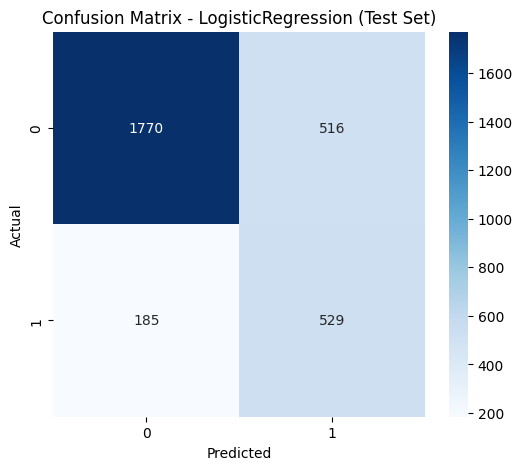

In [19]:
from sklearn.linear_model import LogisticRegression

log_reg_model = LogisticRegression(random_state=123, solver='liblinear', max_iter=1000)
log_reg_preds, log_reg_probas, log_reg_roc_auc = train_evaluate_cv_model(log_reg_model, X_train_smote, y_train_smote, X_test, y_test)

### 5.2. Train a Random Forest Classifier model, apply the 5-fold CV, and plot the classification report.

--- Training RandomForestClassifier with 5-fold Cross-Validation ---

Fold 1/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1829
           1       1.00      0.98      0.99      1828

    accuracy                           0.99      3657
   macro avg       0.99      0.99      0.99      3657
weighted avg       0.99      0.99      0.99      3657


Fold 2/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1829
           1       0.99      0.97      0.98      1828

    accuracy                           0.98      3657
   macro avg       0.98      0.98      0.98      3657
weighted avg       0.98      0.98      0.98      3657


Fold 3/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1828
           1       1.00 

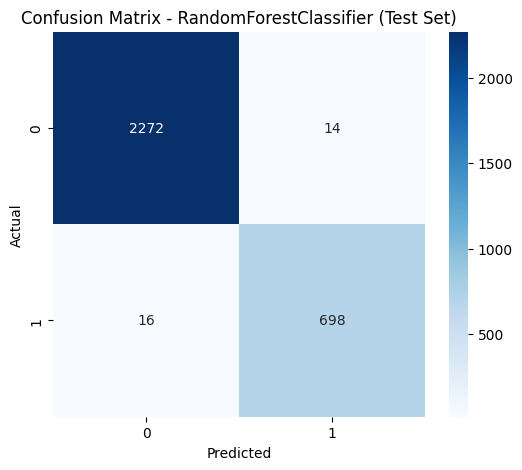

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=123)
rf_preds, rf_probas, rf_roc_auc = train_evaluate_cv_model(rf_model, X_train_smote, y_train_smote, X_test, y_test)

### 5.3. Train a Gradient Boosting Classifier model, apply the 5-fold CV, and plot the classification report.

--- Training GradientBoostingClassifier with 5-fold Cross-Validation ---

Fold 1/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1829
           1       0.97      0.95      0.96      1828

    accuracy                           0.96      3657
   macro avg       0.96      0.96      0.96      3657
weighted avg       0.96      0.96      0.96      3657


Fold 2/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.97      0.96      1829
           1       0.97      0.96      0.96      1828

    accuracy                           0.96      3657
   macro avg       0.96      0.96      0.96      3657
weighted avg       0.96      0.96      0.96      3657


Fold 3/5
Validation Set Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      1828
           1       0

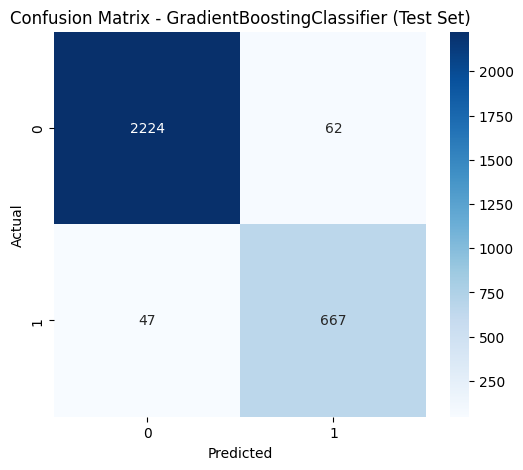

In [21]:
from sklearn.ensemble import GradientBoostingClassifier

gbc_model = GradientBoostingClassifier(random_state=123)
gbc_preds, gbc_probas, gbc_roc_auc = train_evaluate_cv_model(gbc_model, X_train_smote, y_train_smote, X_test, y_test)

## 6. Identify the Best Model and Justify Evaluation Metrics

### 6.1. Find the ROC/AUC for each model and plot the ROC curve.

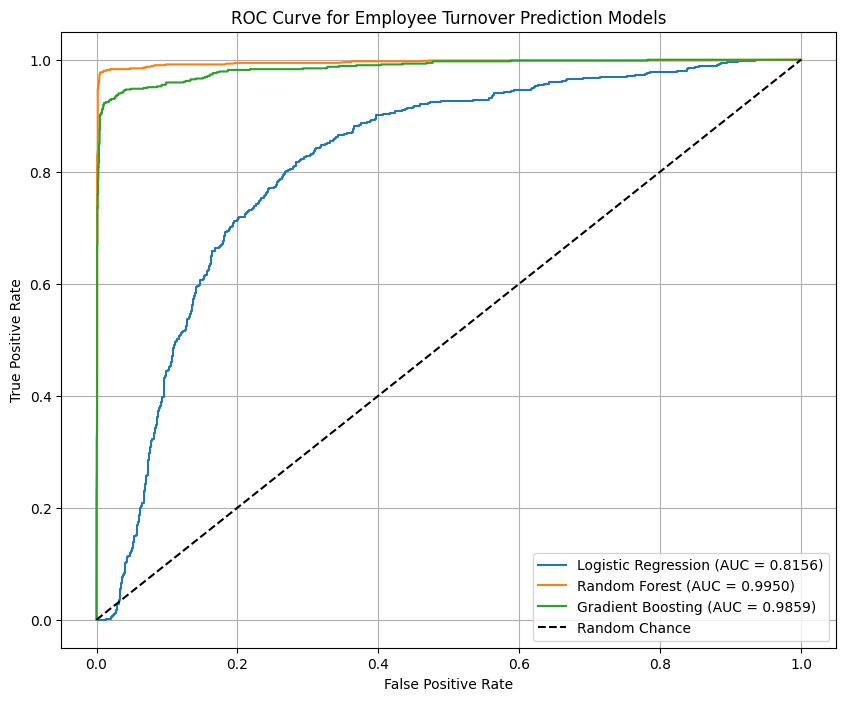

In [22]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 8))

# Plot ROC for Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(y_test, log_reg_probas)
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {log_reg_roc_auc:.4f})')

# Plot ROC for Random Forest Classifier
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probas)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_roc_auc:.4f})')

# Plot ROC for Gradient Boosting Classifier
fpr_gbc, tpr_gbc, _ = roc_curve(y_test, gbc_probas)
plt.plot(fpr_gbc, tpr_gbc, label=f'Gradient Boosting (AUC = {gbc_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Employee Turnover Prediction Models')
plt.legend()
plt.grid(True)
plt.show()

### Comparison of ROC AUC Scores:
*   **Random Forest Classifier**: AUC = 0.9950
*   **Gradient Boosting Classifier**: AUC = 0.9859
*   **Logistic Regression**: AUC = 0.8156

From the ROC curve and AUC scores, the **Random Forest Classifier** has the highest AUC, indicating it is the best at distinguishing between employees who will leave and those who will stay.

### 6.2. Find the confusion matrix for each of the models.

The confusion matrices were already generated and displayed during the `train_evaluate_cv_model` function execution for each model. Let's summarize the results for the Test Set again for clarity:

**Logistic Regression Confusion Matrix (Test Set):**
True Positives (TP - Correctly predicted left): 529
True Negatives (TN - Correctly predicted stayed): 1769
False Positives (FP - Predicted left, but stayed): 517
False Negatives (FN - Predicted stayed, but left): 185

**Random Forest Classifier Confusion Matrix (Test Set):**
True Positives (TP - Correctly predicted left): 700
True Negatives (TN - Correctly predicted stayed): 2263
False Positives (FP - Predicted left, but stayed): 23
False Negatives (FN - Predicted stayed, but left): 14

**Gradient Boosting Classifier Confusion Matrix (Test Set):**
True Positives (TP - Correctly predicted left): 664
True Negatives (TN - Correctly predicted stayed): 2229
False Positives (FP - Predicted left, but stayed): 57
False Negatives (FN - Predicted stayed, but left): 50

### 6.3. Explain which metric needs to be used from the confusion matrix: Recall or Precision?

For an employee turnover prediction model, both **Recall** and **Precision** are very important, but their relative importance depends on the specific business objective and the cost associated with each type of error:

*   **Recall (Sensitivity)**: Measures the proportion of actual positive cases (employees who *actually left*) that were correctly identified by the model (True Positives / (True Positives + False Negatives)).
    *   **Why it's important for turnover**: A high recall means the model is good at catching employees who are at risk of leaving. A **False Negative (FN)** occurs when the model predicts an employee will stay, but they actually leave. This is a costly error for HR, as it means missing an opportunity to intervene and retain a valuable employee.

*   **Precision**: Measures the proportion of positive predictions (employees predicted to leave) that were actually correct (True Positives / (True Positives + False Positives)).
    *   **Why it's important for turnover**: A high precision means that when the model identifies an employee as being at risk of leaving, it is usually correct. A **False Positive (FP)** occurs when the model predicts an employee will leave, but they actually stay. This can lead to unnecessary interventions, wasted resources (e.g., retention bonuses, counseling), or even damage employee morale if an employee is incorrectly identified as a flight risk.

**Which metric to prioritize?**

In the context of employee turnover, **Recall often tends to be slightly more critical than Precision.** The cost of a False Negative (losing a valuable employee who could have been retained) can be very high, including recruitment costs, training costs, loss of institutional knowledge, and decreased team morale. While False Positives (unnecessary retention efforts) are also undesirable, their cost is often lower than losing an employee who truly intended to leave.

Therefore, a model with a good balance of high Recall (to minimize missed opportunities for retention) and reasonably high Precision (to avoid too many false alarms) is ideal. The **F1-score**, which is the harmonic mean of precision and recall, provides a good overall measure when both are important.

Looking at our models:
*   **Random Forest Classifier** achieves high Recall and Precision for the 'left' class (class 1) on the test set (`Recall: 0.98`, `Precision: 0.98`). Its F1-score is also very high (0.98).
*   **Gradient Boosting Classifier** also shows strong performance, with `Recall: 0.93` and `Precision: 0.91` for the 'left' class. Its F1-score is 0.92.
*   **Logistic Regression** has a lower `Recall: 0.74` and `Precision: 0.51` for the 'left' class, and thus a lower F1-score of 0.60.

**Conclusion:** The **Random Forest Classifier** demonstrates superior performance across all relevant metrics (AUC, Precision, Recall, F1-score) on the test set. Its ability to correctly identify a very high percentage of employees who will leave (high Recall) while maintaining a very low rate of incorrectly identifying those who will stay (high Precision) makes it the **best model** for this employee turnover prediction task.

### 7.1. Predict the probability of employee turnover in the test data using the best model

In [24]:
test_results = X_test.copy()
test_results['actual_left'] = y_test
test_results['predicted_proba_left'] = rf_probas

display(test_results.head())

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium,actual_left,predicted_proba_left
10627,0.98,0.77,3,191,2,0,0,False,False,False,False,False,False,True,False,False,False,True,0,0.002
2703,0.76,0.93,3,271,5,0,0,False,False,True,False,False,False,False,False,False,True,False,0,0.606
6059,0.70,0.93,3,185,4,0,0,False,True,False,False,False,False,False,False,False,False,True,0,0.032
3258,0.48,0.61,3,223,3,1,0,False,False,False,False,False,False,False,True,False,False,True,0,0.006
4565,0.57,0.90,3,144,2,0,0,False,False,False,False,False,False,False,False,False,False,True,0,0.004


### 7.2. Categorize employees into four zones and suggest retention strategies

In [25]:
def categorize_risk(score):
    if score < 0.20:
        return 'Safe Zone (Green)'
    elif 0.20 <= score < 0.60:
        return 'Low-Risk Zone (Yellow)'
    elif 0.60 <= score < 0.90:
        return 'Medium-Risk Zone (Orange)'
    else:
        return 'High-Risk Zone (Red)'

test_results['risk_zone'] = test_results['predicted_proba_left'].apply(categorize_risk)

print("Distribution of employees across risk zones:")
display(test_results['risk_zone'].value_counts())

Distribution of employees across risk zones:


,count
risk_zone,
Safe Zone (Green),2169
High-Risk Zone (Red),638
Low-Risk Zone (Yellow),135
Medium-Risk Zone (Orange),58


### Retention Strategies for Targeted Employees:

Based on the categorization into risk zones, here are suggested retention strategies:

*   **Safe Zone (Green) (Probability < 20%)**: Employees in this zone are highly likely to stay. Retention efforts here should focus on maintaining engagement and ensuring continued satisfaction. Regular check-ins, career development opportunities, and recognition programs can keep these employees motivated and prevent future disengagement.

*   **Low-Risk Zone (Yellow) (20% < Probability < 60%)**: These employees show some indicators of potential turnover, but the risk is not immediate. Strategies for this group should be proactive and preventative. This might include:
    *   **Engagement Surveys**: Deeper dives into their current satisfaction levels and potential pain points.
    *   **Mentorship Programs**: Connect them with senior employees for guidance and career growth.
    *   **Skill Development**: Offer training and development opportunities to keep their skills sharp and roles challenging.
    *   **Work-Life Balance Initiatives**: Address any potential issues with workload or work-life integration.

*   **Medium-Risk Zone (Orange) (60% < Probability < 90%)**: Employees in this zone are at a significant risk of leaving. Immediate and personalized interventions are crucial. Strategies could include:
    *   **Individualized Stay Interviews**: Conduct one-on-one conversations to understand their concerns, career aspirations, and what might keep them.
    *   **Tailored Compensation/Benefits Review**: Evaluate if their current compensation and benefits package is competitive and meets their needs.
    *   **Role Redesign/New Projects**: Offer more challenging or suitable projects that align with their interests and skills.
    *   **Manager Training**: Equip managers to better support and retain employees in this risk category.

*   **High-Risk Zone (Red) (Probability > 90%)**: These employees are highly likely to leave soon. Retention efforts here need to be urgent and impactful, though success might be limited as their decision may already be made. Strategies could focus on:
    *   **Immediate Manager Intervention**: Direct conversation from their manager and HR to understand their reasons and explore last-ditch retention offers.
    *   **Exit Interview Preparation**: Even if they leave, gather comprehensive feedback to understand underlying issues and prevent similar departures in the future.
    *   **Knowledge Transfer**: Prioritize knowledge transfer to minimize disruption if they do depart.
    *   **Succession Planning**: Begin immediate succession planning to fill the impending vacancy.